# Part I: The two-dimensional classical Ising model

**Goals**

- 1. Express the partition function as an (infinite) tensor network.
- 2. Approximate it by finite-size environment tensors computed through CTMRG.
- 3. Compute ensamble averages of magnetization and specific heat, including automatic differentiation.
<br>
<br>
<br>

## I.1 2D Stat-mech partition function as a tensor network

We consider Ising model on a square lattice with $J=k_B=1$:

$$
\mathcal H=-\sum_{\langle ij\rangle}\sigma_i\sigma_j-H\sum_i\sigma_i,
\qquad \sigma_i\in\{+1,-1\},\qquad \beta=1/T.
$$

where ${\langle ij\rangle}$ denotes nearest-neighbour sites and $H$ is an external magnetic field.
For $N$ sites, the partition function is

$$
Z_N(\beta,H)=\sum_{\{\sigma\}}
\prod_{\langle ij\rangle}e^{\beta\sigma_i\sigma_j}
\prod_i e^{\beta H\sigma_i}.
$$
<br>

For tensor entries, label the two states by $i=0,1$, with spin values
$\sigma(0)=+1$ and $\sigma(1)=-1$. In code, these are `sigma[i]`.

We construct the partition function by assembling a tensor network with the same square lattice geometry: 
* Each edge carries the Boltzmann weights in a *bond matrix* $h_{ij}=e^{\beta\sigma(i)\sigma(j)}$.
* Ising spins live on vertices. Each vertex carries a "copy" tensor $x_{ijkn}=\delta_{ij}\delta_{ik}\delta_{in}$
and a local field weight $w_i=e^{\beta H\sigma(i)}$.
<br>
<br>

```text
    |     |     |           |    |    |
  --x--h--x--h--x--  =>   --A----A----A--
    |     |     |           |    |    |
    h     h     h           |    |    |
    |     |     |           |    |    |
  --x--h--x--h--x--       --A----A----A--
    |     |     |           |    |    |
```

For $\beta\geq0$, split each *bond matrix* using the symmetric **matrix square root**
$q=h^{1/2}$, with $q q=h$. Absorb four half-bonds into each vertex:

$$
A_{uldr}(\beta,H)
=\sum_{i,j,k,n=0}^{1}
q_{ui}q_{lj}q_{kd}q_{nr}\,x_{ijkn}\,w_i.
$$

The copy tensor enforces $i=j=k=n$, so this simplifies to

$$
A_{uldr}(\beta,H)
=\sum_{i=0}^{1}q_{ui}q_{li}q_{id}q_{ir}\,w_i.
$$
where we order the legs as **up, left, down, right** (`uldr`). The bond dimension is $D=2$;

Contracting all copies of $A$ gives $Z_N$. 



### I.1.1 Construct the site tensors

Build $A(\beta,H)$ with PyTorch and use float64 throughout.
Keep tensor operations in PyTorch so that we can differentiate them later.

The Ising spin degree of freedom `sigma` and copy tensor `x` are defined below.

In [163]:
import numpy as np
import torch
import matplotlib.pyplot as plt

# Set default floating-point precision to float64.
torch.set_default_dtype(torch.float64)

# Set default device to CPU.
# Switch to 'cuda' (Nvidia) or 'mps' (Apple Silicon) if you want to use accelerators)
torch.set_default_device("cpu")

In [164]:
sigma = torch.tensor([1.0, -1.0])
x = torch.zeros((2, 2, 2, 2))
x[0, 0, 0, 0] = x[1, 1, 1, 1] = 1.0


def sqrt_h(beta: float)->torch.Tensor:
    """Return the matrix square root of h[i, j] = exp(beta*sigma[i]*sigma[j]).
    """
    # TODO 1a: Construct h and return its symmetric matrix square root.
    h = torch.exp(beta * torch.outer(sigma, sigma))
    eigenvalues, eigenvectors = torch.linalg.eigh(h)
    return (eigenvectors * torch.sqrt(eigenvalues)) @ eigenvectors.mT

assert torch.isclose((sqrt_h(0.2)-sqrt_h(0.2).T).norm(), torch.tensor(0.0)) , "q=sqrt_h should be symmetric"

def Ising_A(beta: float, H:float = None)->torch.Tensor:
    """Build the partition-function tensor with legs ordered (up, left, down, right).

                         |u(0)
                         sh
                         |U(1)                          u(0)
                         |U(0)                          |
    l(0)--sh--L(1) L(1)--x--R(3) R(0)--sh--r(1) = l(1)--A--r(3)
                         |D(2)                          |
                         |D(0)                          d(2)
                         sh
                         |d(1)

    The number in brackets (i) indicates the position of the index in the tensor.
    The number outside of brackets indicates the label assigned to index when specifying contraction diagram.

    H is the physical magnetic field: the local weight is weights[i] = exp(beta*H*sigma[i]).
    None selects zero field.
    """
    sh = sqrt_h(beta)
    field = torch.as_tensor(beta * (0.0 if H is None else H))
    # TODO 1b: Contract the half-bonds, copy tensor, and the local weights into A[up, left, down, right].
    #          Use torch.einsum (https://docs.pytorch.org/docs/2.14/generated/torch.einsum.html)
    weights = torch.exp(field * sigma)
    A = torch.einsum("uU,lL,Dd,Rr,ULDR,U->uldr", sh, sh, sh, sh, x, weights)
    return A


### I.1.2 Check lattice symmetries

Verify that $A$ is unchanged by $90^\circ$ rotations and reflections.
The four permutations below act on its `uldr` legs.


In [165]:
beta_check = 1.0

A = Ising_A(beta_check)
assert A.shape == (2, 2, 2, 2)
for permutation in [(1, 2, 3, 0), (3, 0, 1, 2), (2, 1, 0, 3), (0, 3, 2, 1)]:
    torch.testing.assert_close(A, A.permute(permutation))
print("Square-lattice symmetries verified.")


Square-lattice symmetries verified.


### I.1.3 Boundary for open boundary conditions

To fully specify the model, we have to specify its boundary conditions.
Here, we consider **open boundary** conditions. Therefore a spin on the corner or an edge of the square lattice 
contributes to parition function as:

```text
    x_2--qq--... => C_0--q--...  and   ...--qq--x_3--qq--... => ...--q--T_0--q--...
    |               |                           |                       |
    q               q                           q                       q
    q               ...                         q                       ...
    |                                           |
    ...                                         ...

    The order of indices of T_0 is chosen to be [left, right, down]
```

where the corner/edge vertices carry the adjusted "copy" tensors $(x_2)_{ij}=\delta_{ij}$ and $(x_3)_{ijk}=\delta_{ij}\delta_{ik}$ respectively.
Here, we can choose to
* pin the spins on the boundary to either up (1) or down (-1).
* keep the spins free.

Construct $C_0$ and $T_0$ by summing over the shared spin index.
Free boundary spins carry the local field weight.

In [166]:
def boundary_tensors(beta: float, H:float= None, pin_to:int=None)->tuple[torch.Tensor]:
    """Build the boundary tensors for the tensor network of the Ising model on a square lattice
    with open boundary conditions.

    pin_to specifies which spin, 1 or -1, to pin at the boundary.
    Pinned boundary spins have zero on-site field energy; bonds are retained.
    """
    assert pin_to in (None, 1, -1), "pin_to must be None, 1, or -1"

    x_2 = torch.zeros((2, 2))
    x_3 = torch.zeros((2, 2, 2))
    field = torch.as_tensor( beta * (0.0 if H is None else H), )
    sh = sqrt_h(beta)

    if pin_to == 1:
        x_2[0, 0] = 1.0
        x_3[0, 0, 0] = 1.0
        weights = (sigma == 1).to(sigma.dtype)
    if pin_to == -1:
        # TODO 1c: Impose down-spin boundary conditions with weights [0, 1].
        x_2[1, 1] = 1.0
        x_3[1, 1, 1] = 1.0
        weights = (sigma == -1).to(sigma.dtype)
    if pin_to is None:
        x_2[0, 0] = x_2[1, 1] = 1.0
        x_3[0, 0, 0] = x_3[1, 1, 1] = 1.0
        weights = torch.exp(field * sigma)

    # Free spins include the field once; pinned spins carry only a selector.
    # C_0= TODO 1c: Construct the corner tensor from x_2, sqrt_h, and weights
    C_0 = torch.einsum("xy,xd,yr,x->dr", x_2, sh, sh, weights)
    # T_0= TODO 1c: Construct the edge tensor from x_3, sqrt_h, and weights, with order of legs [left, right, down]
    T_0 = torch.einsum("xyz,xl,yr,zd,x->lrd", x_3, sh, sh, sh, weights)
    return C_0, T_0

### I.1.4 Validation against exact partition function of a tiny system

In [167]:
# Provided: validate the partition function on finite squares with free and pinned open boundaries.
# Run after completing sqrt_h, Ising_A, and boundary_tensors (Exercises 1a-1c).

def partition_function_tn(L, beta, H, pin_to=None):
    """Exactly contract the L-by-L network of bulk, edge, and corner tensors."""
    A_finite = Ising_A(beta, H)
    C_0, T_0 = boundary_tensors(beta, H, pin_to=pin_to)
    # Assign one integer label to each internal bond. Shared labels are summed.
    horizontal = [[row * (L - 1) + col for col in range(L - 1)]
                  for row in range(L)]
    offset = L * (L - 1)
    vertical = [[offset + row * L + col for col in range(L)]
                for row in range(L - 1)]
    operands = []
    for row in range(L):
        for col in range(L):
            u = vertical[row - 1][col] if row > 0 else None
            l = horizontal[row][col - 1] if col > 0 else None
            d = vertical[row][col] if row < L - 1 else None
            r = horizontal[row][col] if col < L - 1 else None
            # Rotate the top-left corner C_0[d,r] and top edge T_0[l,r,d].
            if row == 0 and col == 0:
                tensor, legs = C_0, [d, r]
            elif row == 0 and col == L - 1:
                tensor, legs = C_0, [l, d]
            elif row == L - 1 and col == L - 1:
                tensor, legs = C_0, [u, l]
            elif row == L - 1 and col == 0:
                tensor, legs = C_0, [r, u]
            elif row == 0:
                tensor, legs = T_0, [l, r, d]
            elif col == L - 1:
                tensor, legs = T_0, [u, d, l]
            elif row == L - 1:
                tensor, legs = T_0, [r, l, u]
            elif col == 0:
                tensor, legs = T_0, [d, u, r]
            else:
                tensor, legs = A_finite, [u, l, d, r]
            operands.extend((tensor, legs))
    # Empty output labels close every bond and return a scalar, without truncation.
    return torch.einsum(*operands, [])

import math
# free open boundary
assert torch.isclose(partition_function_tn(3, 0.2, 0.0), torch.tensor(653.959086968769), rtol=1e-8)
assert torch.isclose(partition_function_tn(3, 0.2, 0.1), torch.tensor(656.087262844221), rtol=1e-8)

# For a pinned $3\times3$ square, all eight perimeter spins (including corners)
# are fixed to $p=+1$ or $p=-1$. Their on-site field energies are set to zero;
# all nearest-neighbor interactions remain. Only the center index $i=0,1$ is summed, with spin value $\sigma(i)$.
# Eight perimeter bonds contribute $8$, and the four center-to-boundary bonds
# contribute $4p\sigma(i)$. Thus the Hamiltonian and exact partition function are
assert torch.isclose(partition_function_tn(3, 0.2, 0.0, pin_to=1), torch.tensor(2*math.exp(8*0.2)*math.cosh(0.2*4)), rtol=1e-8)
assert torch.isclose(partition_function_tn(3, 0.2, 0.0, pin_to=-1), torch.tensor(2*math.exp(8*0.2)*math.cosh(-0.2*4)), rtol=1e-8)


## I.2 Approximate contraction of infinite TN: CTMRG

Evaluating partition function $Z_N$, represented as tensor network, by *exact* contraction is exponentially hard for large $N$.
The goal here is to employ real-space renormalization group approach to instead build a finite and controlled approximation of $Z_N$.

```text

Z_N = C_0--T_0--...--T_0--C_0  \approx  C*--T*--C*  
      |    |         |    |             |   |   |
      T_0--A--  ...  A----T_0           T*--A---T*
      |    |         |    |             |   |   |
      ...            ...                C*--T*--C*
      |    |         |    |
      T_0--A--  ...  A----T_0
      |    |         |    |
      C_0--T_0--...--T_0--C_0
```

where $C^*$ and $T^*$ are finite tensors, with sizes $\chi\times\chi$ and $\chi\times\chi\times D$ respectively. The $\chi$ is dubbed 
*environment* dimension and it will control the precision of approximation.

The renormalization process seeks a fixed point tensor $C^*$, $T^*$ of the map

```text
                       C---T---T---T---C
                       |   |   |   |   |
C--T--C => enlarge =>  T---A---A---A---T => truncate & absorb => C'--T'--C'
|  |  |                |   |   |   |   |                         |   |   |
T--A--T                T---A---A---A---T                         T'--A---T'
|  |  |                |   |   |   |   |                         |   |   |
C--T--C                T---A---A---A---T                         C'--T'--C'
                       |   |   |   |   |
                       C---T---T---T---C
```

The key step worked-out below is the truncation and absorption.


### I.2.1 Initialize the CTM boundary

Represent the initial environment by a corner matrix $C$ and an edge tensor $T$.
Square-lattice symmetry of the network and point-group symmetries of the on-site tensor `Ising_A` lets us use the same tensors in all four directions.

| Tensor | Shape | Meaning |
|---|---|---|
| $C$ | $(b,b)$ | Corner |
| $T$ | $(b,b,D)$ | Edge |

Here $b\leq\chi$ is the current boundary dimension; $\chi$ is the truncation cap.

```text
    C--1           0---T---1
    |                  |
    0                  2
```

Two starting environments:

- **Open boundary:** These are `C_0` and `T_0` from section I.1.3
- **Random boundary:** draw random entries and symmetrize $C$ and the first
  two legs of $T$. This gives reflection-symmetric starting tensors.

Random boundaries can select either magnetization branch below $T_c$.
We use them in the observable scans.

In [168]:
def init_obc_CT(beta: float, H: float = None, pin_to: int = None):
    """Build open boundaries.

    Return C.shape == (2, 2) and T.shape == (2, 2, 2). Subsequent CTMRG
    updates grow the active dimension up to chi without padding zero states.
    """
    return boundary_tensors(beta, H, pin_to)


def init_rand_CT(A, chi):
    """Build random boundaries with C and each T[:, :, k] real and symmetric."""

    C = torch.rand((chi, chi), dtype=A.dtype, device=A.device)
    T = torch.rand((chi, chi, A.shape[0]), dtype=A.dtype, device=A.device)

    # TODO 2a: Symmetrize C and the first two legs of T.
    C = (C + C.T)/2
    T = (T + T.permute(1, 0, 2))/2

    return C, T


### I.2.2 Enlarge, truncate, and absorb

A **corner transfer matrix renormalization group (CTMRG)** step absorbs one
layer, then compresses the boundary back to at most $\chi$ states.

```text
    C---T---T---T---C
    |   |   |   |   |
    T---A---A---A---T
    |   |   |   |   |
    T---A---A---A---T
    |   |   |   |   |
    T---A---A---A---T
    |   |   |   |   |
    C---T---T---T---C
```

#### 1. Enlarge the corner

Contract one corner, two edges, and on-site tensor.
Pair the open legs to form a $(bD)\times(bD)$ matrix $C'$:

```text
    C---T--        C'==
    |   |     =    ||
    T---A--
    |   |
```

In [169]:
def enlarged_C(A, C, T):
    r"""
    Build enlarged corner tensor

        C----b(1) b(0)---T--c(1) = C'==c(2),h(3)
        a(0)             d(2)      ||
        a(1)             d(0)      e(0),g(1)
        T--f(2) f(1)-----A--h(3)
        e(0)             g(2)

    The number in brackets (x) indicates the position of the index in the tensor.
    The number outside of brackets indicates the label assigned to index when specifying contraction diagram.
    We choose the following order of indices for the enlarged corner: [boundary down, on-site down, boundary right, on-site right]
    """

    # TODO 2b: Contract the enlarged corner using the indexed diagram.
    return torch.einsum("ab,bcd,eaf,dfgh->egch", C, T, T, A)


### 3.2. Truncate and update the edge

Diagonalize the real symmetric enlarged corner:

$$
C'=U'\operatorname{diag}(S')U'^T.
$$

Keep $r=\min(\chi,bD)$ eigenvectors with the largest eigenvalue magnitudes.
They form an isometry $U\in\mathbb R^{bD\times r}$, with $U^TU=I_r$.

The approximation $U\operatorname{diag}(S)U^T$ minimizes the Frobenius error
among rank-$r$ matrices. In the retained basis, the new corner is diagonal:

$$
C_{\mathrm{new}}=U^TC'U=\operatorname{diag}(S).
$$

For the edge, absorb one $A$ and compress both enlarged boundary legs using $U$.
The bulk leg remains open:

```text
              |
          ----U----
          |       |             |
          T-------A--    =    T_new--
          |       |             |
          ----U----
              |
```

The indexed diagram in `T_absorb` specifies the leg ordering.


In [170]:
def compress(chi, enlarged_C):
    r"""
    Return the retained eigenvalues S and the truncation isometry U.

    The input has shape (b, D, b, D), where b is the current boundary
    dimension. Retain at most min(chi, b*D) eigenvectors,
    ordered by decreasing eigenvalue magnitude. S is a vector of eigenvalues, not a matrix.
    """

    left_chi, left_D, right_chi, right_D = enlarged_C.shape
    matrix = enlarged_C.reshape(left_chi * left_D, right_chi * right_D)
    # TODO 2c: Diagonalize matrix and choose indices for the largest \chi (in magnitude) eigenvalues.
    #          (Use https://docs.pytorch.org/docs/2.14/generated/torch.linalg.eigh.html
    #           and https://docs.pytorch.org/docs/2.14/generated/torch.argsort.html)
    S, U = torch.linalg.eigh(matrix)
    indices = torch.argsort(S.abs(), descending=True)[:chi]
    S = S[indices]
    U = U[:, indices].reshape(left_chi, left_D, len(indices))
    return S, U


def T_absorb(A, T, U):
    r"""
    Absorb on-site tensor into the edge tensor and compress with the corner isometry.

        g(2)
        U
        |------------\
        b(0)          f(1)
        b(1)          f(0)      g(1)
        T--c(2) c(1)--A--h(3) = T--h(2)
        a(0)          e(2)      d(0)
        a(0)          e(1)
        |------------/
        U
        d(2)
    """
    # TODO 2d: Absorb A into T and project both enlarged boundary legs with U.
    return torch.einsum("abc,bfg,fceh,aed->dgh", T, U, A, U)


### 3.3. Compose one CTMRG step

Combine corner enlargement, truncation, and edge absorption.
Store $C_{\mathrm{new}}$ in its diagonal basis.


In [171]:
def ctm_iter(A, C, T, chi):
    r"""
    Perform one CTMRG step, retaining at most chi boundary states.
    """
    # TODO 2e: Combine enlargement, truncation, and edge absorption into one step.
    #          Given current C,T i)   compute enlarged corner
    #                            ii)  compute the isometry and truncated enlarged corner,
    #                                embed the 1D truncated spectrum of C' into a diagonal matrix
    #                            iii) compute renormalized edge tensor T
    S, U = compress(chi, enlarged_C(A, C, T))
    C_n = torch.diag(S)
    T_n = T_absorb(A, T, U)
    return C_n, T_n


## 4. Iterate to a fixed point

After each update:

1. Normalize $C$ and $T$ by their largest absolute entries.
2. Symmetrize the first two legs of $T$ to suppress roundoff errors.
3. Compare consecutive normalized corner spectra, sorted by eigenvalue magnitude.

Stop when the summed absolute spectrum difference is below the tolerance.
If the iteration cap is reached, the environment may still be unconverged.

Scalar normalizations cancel in the observable ratios below.
Finite-$\chi$ errors remain: check larger $\chi$ near the transition.


In [172]:
def ctmrg(
    A,
    C,
    T,
    chi,
    ctm_max_iter=100,
    ctm_conv_tol=1.0e-8,
    callback=None,
    raise_on_nonconvergence=False,
):
    """Iterate CTMRG, retaining at most chi states.

    callback(i, residual, finished, A, C, T) monitors each update.
    finished marks convergence or the final allowed iteration.
    Smaller initial boundaries grow up to chi. The stopping test uses no_grad.
    """

    with torch.no_grad():
        spectrum = torch.linalg.eigvalsh(C)
        indices = torch.argsort(spectrum.abs(), descending=True)
        previous_spectrum = spectrum[indices] / spectrum.abs().max()

    for i in range(ctm_max_iter):
        # TODO 1: Perform one update using ctm_iter.
        C, T = ctm_iter(A, C, T, chi)
        # TODO 2: Normalize C by its largest absolute entry.
        C = C / C.abs().max()
        # TODO 3: Symmetrize the first two legs of T, then normalize T.
        T = (T + T.permute(1, 0, 2)) / 2
        T = T / T.abs().max()

        # Compute the corner spectrum difference
        with torch.no_grad():
            spectrum = C.diagonal()
            indices = torch.argsort(spectrum.abs(), descending=True)
            spectrum = spectrum[indices]
            # Boundary dimensions may grow during the first few updates.
            size = max(spectrum.numel(), previous_spectrum.numel())
            current_padded = torch.nn.functional.pad(
                spectrum, (0, size - spectrum.numel())
            )
            previous_padded = torch.nn.functional.pad(
                previous_spectrum, (0, size - previous_spectrum.numel())
            )
            residual = (current_padded - previous_padded).abs().sum()
            converged = bool(residual < ctm_conv_tol)
            previous_spectrum = spectrum

        if callback is not None:
            finished = converged or i == ctm_max_iter - 1
            callback(i, residual, finished, A, C, T)
        if converged:
            break

    if raise_on_nonconvergence and not converged:
        raise RuntimeError(
            f"CTMRG did not converge in {ctm_max_iter} iterations: "
            f"residual={residual.item():.3e}, tolerance={ctm_conv_tol:.3e}."
        )
    return C, T


In [173]:
# Sanity check away from criticality, with reproducible random boundaries.
torch.manual_seed(0)
beta_check = 0.2
chi_check = 8
A_check = Ising_A(beta_check)
C_check, T_check = init_rand_CT(A_check, chi_check)
C_check, T_check = ctmrg(
    A_check, C_check, T_check, chi_check,
    ctm_conv_tol=1e-10, raise_on_nonconvergence=True,
)

assert C_check.shape == (chi_check, chi_check)
assert T_check.shape == (chi_check, chi_check, A_check.shape[0])
assert torch.isfinite(C_check).all() and torch.isfinite(T_check).all()

# Check the spectrum: individual entries of T depend on the eigenvector signs.
expected_spectrum = torch.tensor(
    [1.0, 2.06116860e-1, 8.75670164e-3, 1.80490385e-3,
     3.72021107e-4, 7.66798078e-5, 1.58033616e-5, 3.25766035e-6],
    dtype=C_check.dtype, device=C_check.device,
)
torch.testing.assert_close(
    C_check.diagonal().abs().sort(descending=True).values,
    expected_spectrum, rtol=1e-4, atol=1e-8,
)
print("CTMRG converged and returned finite tensors.")
print("C shape:", tuple(C_check.shape), "; T shape:", tuple(T_check.shape))
print("Normalized corner spectrum:", C_check.diagonal())


CTMRG converged and returned finite tensors.
C shape: (8, 8) ; T shape: (8, 8, 2)
Normalized corner spectrum: tensor([1.0000e+00, 2.0612e-01, 8.7567e-03, 1.8049e-03, 3.7202e-04, 7.6680e-05,
        1.5803e-05, 3.2577e-06])


## 5. Measure the magnetization

Insert the spin value $\sigma(i)$ into the local weight to obtain the impurity tensor $B$:

$$
B_{uldr}(\beta,H)
=\sum_{i,j,k,n=0}^{1}
q_{ui}q_{lj}q_{kd}q_{nr}\,x_{ijkn}\,w_i\,\sigma(i).
$$

Using the copy constraint again gives

$$
B_{uldr}(\beta,H)
=\sum_{i=0}^{1}q_{ui}q_{li}q_{id}q_{ir}\,w_i\,\sigma(i).
$$

Contract four corners and four edges into the one-site environment
$\rho_{uldr}$. The magnetization is the normalized contraction

$$
m=\langle\sigma_i\rangle
=\frac{\sum_{uldr}\rho_{uldr}B_{uldr}}
       {\sum_{uldr}\rho_{uldr}A_{uldr}}.
$$

```text
       C---T---C         C---T---C
       |   |   |         |   |   |
  m =  T---B---T    /    T---A---T
       |   |   |         |   |   |
       C---T---C         C---T---C
```

Use the same $\beta$ and $H$ for $A$ and $B$.


In [174]:
def f_B(beta, H=None):
    r"""
    Build the magnetization impurity tensor B at the same beta and H as A.
    """
    h = sqrt_h(beta)
    field = torch.as_tensor(
        beta * (0.0 if H is None else H), dtype=sigma.dtype, device=sigma.device
    )
    # TODO 3a: Include sigma in the local weights and contract the impurity tensor B.
    weights = torch.exp(field * sigma) * sigma
    B = torch.einsum("uU,lL,Dd,Rr,ULDR,U->uldr", h, h, h, h, x, weights)
    return B


def aux_rho_1x1(C, T):
    r"""
    Contract four corners and four edges into rho[up, left, down, right].

        i) C--b(1) b(0)--T--c(1) = C-----T--c(1)
           |             |         |     |
           a(0)          d(2)      a(0)  d(2)

        ii) C-----T--b(1) b(0)--C  =  C----T--------C
            |     |             |     |    |        |
            a(0)  c(2)          |     a(0) c(2)     |
                          e(2)--T             e(3)--T
                                |                   |
                              d(1)                  d(1)

        iii) C------T--------C                C------T--------C
             a(0)   |        |                |      |        |
             a(1)   u(2)     |                |      u(0)     |
             T---l(3)  r(3)--T        =       T---l(1)  r(3)--T
             |      d(2)     b(1)             |      d(2)     |
             |      |        b(0)             |      |        |
             C------T--------C                C------T--------C
    """
    # TODO 3b: Form rho using diagram (i).
    rho = torch.einsum("ab,bcd->acd", C, T)
    # TODO 3b: Join the corner-edge blocks as in diagram (ii).
    rho = torch.einsum("abc,bde->adce", rho, rho)
    # TODO 3b: Close the boundary as in diagram (iii), with the site legs ordered as uldr.
    rho = torch.einsum("abur,badl->uldr", rho, rho)
    return rho


def eval_1x1(B, A, rho):
    r"""
    Return the normalized expectation value of B in the environment rho.
    """
    # TODO 3c: Return the normalized impurity contraction.
    return torch.einsum("uldr,uldr", rho, B) / torch.einsum("uldr,uldr", rho, A)


## 6. Compare with the exact magnetization

At zero field, the critical inverse temperature is

$$
\beta_c=\frac12\log(1+\sqrt2).
$$

The positive spontaneous-magnetization branch is

$$
m_{\mathrm{exact}}(\beta)=
\begin{cases}
0,&\beta\leq\beta_c,\\
\left[1-\sinh^{-4}(2\beta)\right]^{1/8},&\beta>\beta_c.
\end{cases}
$$

- A finite spin-symmetric system has $m=0$ at $H=0$.
- Spontaneous magnetization takes the thermodynamic limit before $H\to0^+$.
- Random boundaries select either sign, so compare $|m|$ with the positive branch.

Use a fixed seed for reproducibility. Check the final convergence residual at
each temperature.


In [175]:
def report_ctm(i, residual, finished, A, C, T):
    """Print the final iteration count and corner-spectrum residual."""
    if finished:
        print(f"iterations={i + 1}, residual={residual.item():.2e}")


torch.manual_seed(7)
chi = 12
betas = np.linspace(0.1, 0.6, 20)
magnetizations = []

with torch.no_grad():
    for beta in betas:
        print(f"beta={beta:.4f}", end=", ")
        A = Ising_A(beta)
        C, T = ctmrg(
            A,
            *init_rand_CT(A, chi),
            chi,
            ctm_max_iter=3000,
            ctm_conv_tol=1.0e-8,
            callback=report_ctm,
        )
        m = eval_1x1(f_B(beta), A, aux_rho_1x1(C, T))
        magnetizations.append(m.item())


beta=0.1000, iterations=6, residual=2.10e-09
beta=0.1263, iterations=7, residual=4.02e-09
beta=0.1526, iterations=8, residual=5.08e-09
beta=0.1789, iterations=9, residual=6.57e-09
beta=0.2053, iterations=11, residual=1.84e-09
beta=0.2316, iterations=12, residual=5.34e-09
beta=0.2579, iterations=14, residual=4.37e-09
beta=0.2842, iterations=16, residual=8.22e-09
beta=0.3105, iterations=20, residual=9.64e-09
beta=0.3368, iterations=32, residual=9.35e-09
beta=0.3632, iterations=44, residual=9.92e-09
beta=0.3895, iterations=61, residual=9.83e-09
beta=0.4158, iterations=97, residual=8.89e-09
beta=0.4421, iterations=1380, residual=9.93e-09
beta=0.4684, iterations=115, residual=8.84e-09
beta=0.4947, iterations=490, residual=7.12e-09
beta=0.5211, iterations=235, residual=9.66e-09
beta=0.5474, iterations=1679, residual=4.03e-09
beta=0.5737, iterations=164, residual=6.16e-09
beta=0.6000, iterations=103, residual=1.29e-09


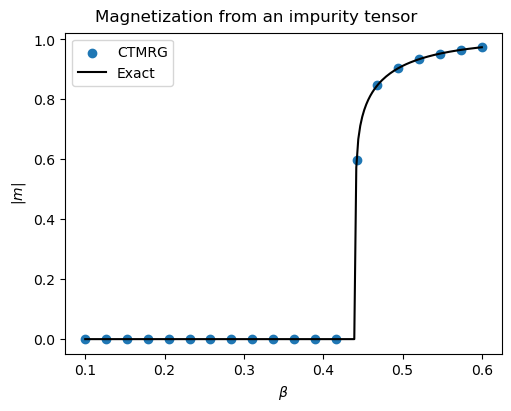

In [176]:
def exact_magnetization(beta):
    """Return the positive spontaneous magnetization, including the disordered phase."""
    beta = np.asarray(beta, dtype=float)
    beta_c = np.log1p(np.sqrt(2)) / 2
    ordered = beta > beta_c
    result = np.zeros_like(beta)
    result[ordered] = (1 - np.sinh(2 * beta[ordered]) ** (-4)) ** (1 / 8)
    return result


def plot_magnetization(betas, values, title):
    """Compare |m| with the exact zero-field magnetization."""
    values = np.abs(np.asarray(values, dtype=float))
    beta_grid = np.linspace(betas.min(), betas.max(), 200)
    fig, ax = plt.subplots(1, 1, figsize=(5, 4), constrained_layout=True)
    ax.scatter(betas, values, label="CTMRG")
    ax.plot(beta_grid, exact_magnetization(beta_grid), color="black", label="Exact")
    ax.set(xlabel=r"$\beta$", ylabel=r"$|m|$")
    ax.legend()
    fig.suptitle(title)
    return fig, ax


fig_impurity, ax_impurity = plot_magnetization(
    betas, magnetizations, "Magnetization from an impurity tensor"
)
plt.show()


## 7. Compute the partition function per site

The partition function per site $z$ and the free energy per site $f$ are

$$
z=\lim_{N\to\infty}Z_N^{1/N},\qquad
\log z=\lim_{N\to\infty}\frac{\log Z_N}{N},\qquad
f=-\frac{\log z}{\beta},
$$

where $N$ is the total number of sites.

### 7.1. Contract four patches

A single patch contraction depends on the normalization of $C$ and $T$,
which are rescaled at every CTMRG step.
To cancel these scale factors, form four scalars from the **same converged environment**:

```text
       C---T---C              C-------C
       |   |   |              |       |
  Z1 = T---A---T         Z2 = |       |
       |   |   |              |       |
       C---T---C              C-------C

       C---T---C              C-------C
       |   |   |              |       |
  Z3 = |   |   |         Z4 = T-------T
       |   |   |              |       |
       C---T---C              C-------C
```

The partition function per site is estimated by

$$
\boxed{z=\frac{Z_1Z_2}{Z_3Z_4}}.
$$

To motivate the ratio, imagine that $C$ represents an $L\times L$ quadrant
and $T$ a strip of length $L$. The four patches have areas
$(2L+1)^2$, $(2L)^2$, $2L(2L+1)$, and $2L(2L+1)$, respectively.
Keeping only the bulk contribution $Z\sim z^{\mathrm{area}}$ gives

$$
\frac{Z_1 Z_2}{Z_3 Z_4} \simeq z^{(2L+1)^2+(2L)^2-2(2L)(2L+1)} = z.
$$

Importantly, the formula is insensitive to the normalization of $C$ and $T$.
Specifically, under $C\mapsto cC$ and $T\mapsto tT$,

$$
Z_1\mapsto c^4t^4Z_1,\quad Z_2\mapsto c^4Z_2,\quad
Z_3\mapsto c^4t^2Z_3,\quad Z_4\mapsto c^4t^2Z_4.
$$
These scale factors cancel exactly in the ratio, so no CTMRG normalization history is needed.
Rotational symmetry gives $Z_3=Z_4$, so compute this contraction once.


In [177]:
def partition_contractions(A, C, T):
    """Return Z1, Z2, Z3, Z4 from the four CTM diagrams above.

    Assumes real, reflection-symmetric tensors shared by all directions.
    Consequently the two rectangular contractions satisfy Z3 == Z4.
    """
    rho = aux_rho_1x1(C, T)
    # TODO: Contract rho with A to obtain scalar Z1.
    Z1 = torch.einsum("uldr,uldr->", rho, A)
    # TODO: Close four corner matrices into the empty-patch scalar Z2.
    Z2 = torch.trace(torch.linalg.matrix_power(C, 4))

    # TODO: Contract the rectangular patch to obtain scalar Z3.
    # One half of a rectangular patch: two corners and one edge.
    half_rectangle = torch.einsum("xy,yz,zwp->xpw", C, C, T)
    Z3 = torch.einsum("xpw,wpx->", half_rectangle, half_rectangle)
    Z4 = Z3  # Rotational symmetry, not a separate approximation.
    return Z1, Z2, Z3, Z4


def eval_log_z(A, C, T):
    """Estimate log(z) = -beta*f from a converged isotropic CTM environment.

    The four scalar contractions are positive for the physical environment.
    Scalar rescalings of C and T cancel; a rescaling of A does not.
    """
    # TODO: Combine the four patch contractions in logarithmic form.
    Z1, Z2, Z3, Z4 = partition_contractions(A, C, T)
    return Z1.log() + Z2.log() - Z3.log() - Z4.log()


def eval_z(A, C, T):
    """Estimate z = lim Z_N**(1/N), the partition function per site."""
    # TODO: Recover z from eval_log_z.
    return eval_log_z(A, C, T).exp()


## 8. Observables from automatic differentiation

Magnetization, energy per site, and specific heat follow from derivatives of $\log z$.
At $H=0$,

$$
m=\frac1\beta\frac{\partial\log z}{\partial H},\qquad
u=-\frac{\partial\log z}{\partial\beta},\qquad
c_V=\frac{\partial u}{\partial T}
=\beta^2\frac{\partial^2\log z}{\partial\beta^2}.
$$

PyTorch records the operations that connect $\beta$ and $H$ to $\log z$,
including the CTMRG iterations.
The function [`torch.autograd.grad`](https://docs.pytorch.org/docs/stable/generated/torch.autograd.grad.html)
applies the chain rule through this computation graph to evaluate the derivatives automatically. In the following,
use this function to compute the observables mentioned. Two options are needed here:
- `retain_graph=True`: preserve the graph after the field derivative so it can be reused for the temperature derivatives.
- `create_graph=True`: record the first temperature derivative so it can be differentiated again.

Random boundaries can select a magnetization branch below $T_c$.
Second derivatives require careful convergence; check the CTMRG tolerance and $\chi$.


In [178]:
def obs_from_AD(betas, chi, ctm_max_iter=10000, ctm_conv_tol=1e-9):
    """Return zero-field magnetization and specific heat from derivatives of log(z)."""
    m_ad = []
    cv_ad = []

    for beta_value in betas:
        H = torch.zeros((), dtype=sigma.dtype, requires_grad=True)
        beta = torch.tensor(beta_value, dtype=sigma.dtype, requires_grad=True)
        A = Ising_A(beta, H)
        C, T = ctmrg(
            A,
            *init_rand_CT(A, chi),
            chi,
            ctm_max_iter=ctm_max_iter,
            ctm_conv_tol=ctm_conv_tol,
            raise_on_nonconvergence=True,
        )
        log_z = eval_log_z(A, C, T)
        # Reuse this graph for the temperature derivatives.
        # TODO: Compute dlog_z_dH, retaining the graph for the temperature derivatives.
        (dlog_z_dH,) = torch.autograd.grad(log_z, H, retain_graph=True)
        m_ad.append((dlog_z_dH / beta).item())

        # Keep the first derivative differentiable to obtain c_V.
        # TODO: Compute dlog_z_dbeta and keep its derivative graph.
        (dlog_z_dbeta,) = torch.autograd.grad(log_z, beta, create_graph=True)
        # TODO: Differentiate dlog_z_dbeta again to obtain d2log_z_dbeta2.
        (d2log_z_dbeta2,) = torch.autograd.grad(dlog_z_dbeta, beta)
        cv_ad.append((beta**2 * d2log_z_dbeta2).item())

    return m_ad, cv_ad


### 8.1. Exact specific heat (reference)

Use the zero-field square-lattice formula below. Its logarithmic divergence
marks $\beta_c$; finite $\chi$ limits accuracy near the peak.

Reference: [Caux, Eq. (126)](https://jscaux.org/static/jsc/courses/2019_FPITFT/FROM_PI_TO_FT_2019_notes.pdf).


In [179]:
def exact_specific_heat(beta):
    """Exact zero-field specific heat per site for beta > 0 and J = k_B = 1."""
    from scipy.special import ellipk, ellipe

    beta = np.asarray(beta, dtype=float)
    t = np.tanh(2 * beta)
    k = 2 * t / np.cosh(2 * beta)
    K, E = ellipk(k**2), ellipe(k**2)  # SciPy uses the parameter k**2.
    return (
        4
        / np.pi
        * (beta / t) ** 2
        * (K - E - (1 - t**2) * (np.pi / 2 + (2 * t**2 - 1) * K))
    )


def plot_specific_heat(betas, values):
    """Compare CTMRG specific heat with the exact zero-field curve."""
    betas = np.asarray(betas)
    grid = np.linspace(betas.min(), betas.max(), 400)
    fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
    ax.plot(grid, exact_specific_heat(grid), color="black", label="Exact")
    ax.scatter(betas, values, label="CTMRG")
    ax.axvline(
        np.log1p(np.sqrt(2)) / 2, color="gray", linestyle="--", label=r"$\beta_c$"
    )
    ax.set(xlabel=r"$\beta$", ylabel=r"$c_V$", title="Specific heat per site")
    ax.legend()
    return fig, ax


### 8.2. Compare both observables

Sample more densely near $\beta_c$ and compare the AD results with the exact curves.


In [180]:
torch.manual_seed(7)
chi = 12
betas = np.concatenate(
    [np.linspace(0.3, 0.41, 5), np.linspace(0.43, 0.45, 10), np.linspace(0.48, 0.6, 5)]
)
m_ad, cv_ad = obs_from_AD(betas, chi)


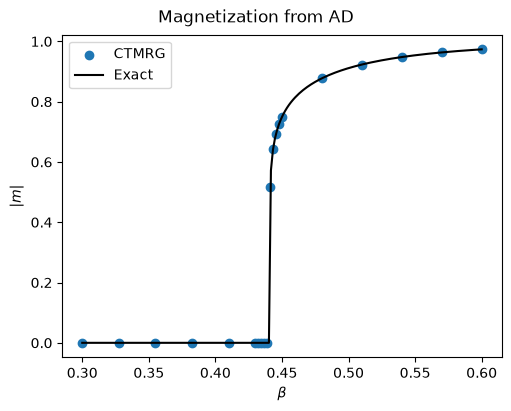

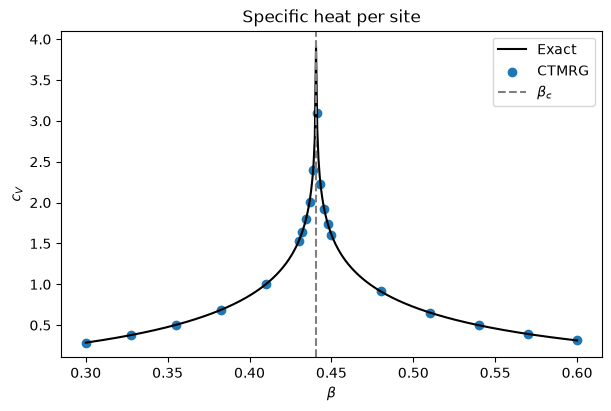

In [20]:
fig_m, ax_m = plot_magnetization(betas, m_ad, "Magnetization from AD")
fig_heat, ax_heat = plot_specific_heat(betas, cv_ad)

plt.show()


## 9. Critical slowing down

Long correlations require more CTMRG updates to resolve. Compare temperatures
using fixed $\chi$, tolerance, and random starting tensors.

Build an effective one-column transfer matrix from two edges and one site:

```text
    a---T---b
        | u
    l---A---r
        | v
    c---T---d
```

Group $(a,c,l)$ and $(b,d,r)$ into matrix indices. From its two largest
eigenvalue magnitudes, estimate the correlation length in lattice spacings:

$$
\mathcal E_{(acl),(bdr)}=\sum_{uv}T_{abu}A_{ulvr}T_{cdv},\qquad
\xi=-\frac{1}{\log|\lambda_1/\lambda_0|}.
$$

Runtime below measures **CTMRG only**, excluding transfer-matrix diagonalization.
Finite $\chi$ rounds the divergence and can shift the peak away from $\beta_c$.


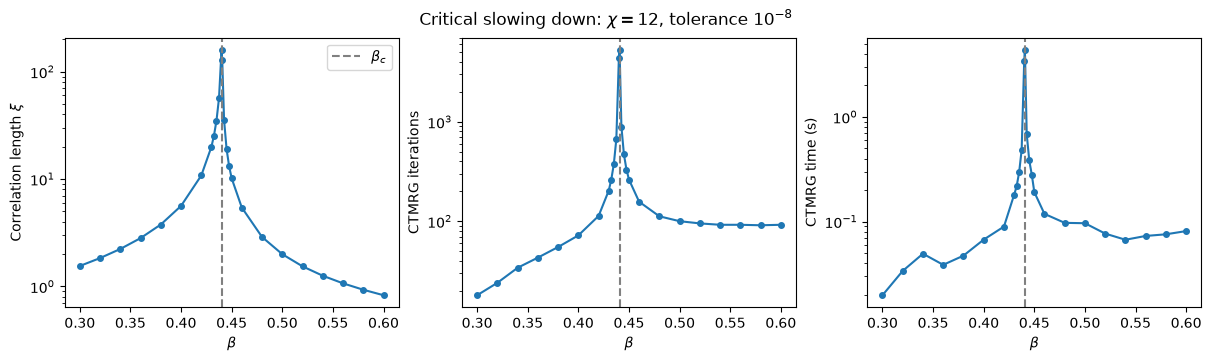

At beta_c: xi=128.5, iterations=5279, time=4.35 s


In [21]:
from time import perf_counter


def correlation_length(A, T):
    """Estimate the dominant transfer correlation length in lattice spacings."""
    b, _, D = T.shape
    transfer = torch.einsum("abu,ulvr,cdv->aclbdr", T, A, T)
    transfer = transfer.reshape(b * b * D, b * b * D)
    eigenvalues = torch.linalg.eigvalsh(transfer).abs().sort(descending=True).values
    return (-1 / torch.log(eigenvalues[1] / eigenvalues[0])).item()


chi_scan = 12
ctm_tol_scan = 1.0e-8
beta_c = np.log1p(np.sqrt(2)) / 2
betas_scan = np.unique(
    np.r_[np.linspace(0.3, 0.6, 16), np.linspace(0.43, 0.45, 9), beta_c]
)
ctm_iterations = []
ctm_seconds = []
correlation_lengths = []


def record_iterations(i, residual, finished, A, C, T):
    if finished:
        ctm_iterations.append(i + 1)


with torch.no_grad():
    for beta_scan in betas_scan:
        # Identical random starting tensors at each beta; no warm starts.
        torch.manual_seed(7)
        A_scan = Ising_A(beta_scan)
        C0, T0 = init_rand_CT(A_scan, chi_scan)
        start = perf_counter()
        C_scan, T_scan = ctmrg(
            A_scan,
            C0,
            T0,
            chi_scan,
            ctm_max_iter=10000,
            ctm_conv_tol=ctm_tol_scan,
            callback=record_iterations,
            raise_on_nonconvergence=True,
        )
        ctm_seconds.append(perf_counter() - start)
        correlation_lengths.append(correlation_length(A_scan, T_scan))

fig_convergence, axes_convergence = plt.subplots(
    1, 3, figsize=(12, 3.5), sharex=True, constrained_layout=True
)
for ax, values, label in zip(
    axes_convergence,
    [correlation_lengths, ctm_iterations, ctm_seconds],
    [r"Correlation length $\xi$", "CTMRG iterations", "CTMRG time (s)"],
):
    ax.plot(betas_scan, values, "o-", markersize=4)
    ax.axvline(beta_c, color="gray", linestyle="--", label=r"$\beta_c$")
    ax.set(xlabel=r"$\beta$", ylabel=label, yscale="log")
axes_convergence[0].legend()
fig_convergence.suptitle(
    rf"Critical slowing down: $\chi={chi_scan}$, tolerance $10^{{-8}}$"
)
plt.show()

j = np.argmin(np.abs(betas_scan - beta_c))
print(
    f"At beta_c: xi={correlation_lengths[j]:.1f}, "
    f"iterations={ctm_iterations[j]}, time={ctm_seconds[j]:.2f} s"
)
